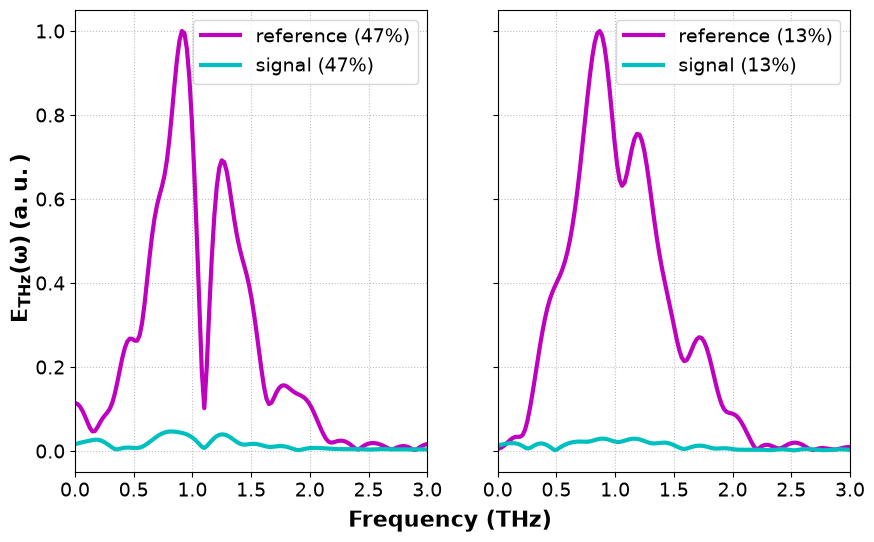

In [ ]:
# comparison plots of humidity 
import matplotlib.pyplot as plt
import numpy.fft as fft
import numpy as np
import os
from pprint import pprint

file_root = '/Users/yuewang/SLAC/goldthz/processed_data/single_shot/'

wp = 'wp43'
pos = 'pos10'

def fetch_avg_std(wp, pos):
    f_ffts = []
    r_ffts = []
    s_ffts = []

    for shot in range(4):
        file_path = file_root + f'SS_Au_{wp}_{pos}_shot_{shot:04d}/'
        if not os.path.exists(file_root + f'SS_Au_{wp}_{pos}_shot_{shot:04d}/'):
                continue
        # load data
        post_bal_raw = np.loadtxt(file_path + 'THz_post_bal.dat')
        post_bal = np.mean(post_bal_raw, axis=1)  # average over the columns
        shot_bal = np.loadtxt(file_path + 'THz_shot_bal.dat')
        time_axis = np.loadtxt(file_path + 'time_axis.dat')

        # compute frequency axis 
        dt = time_axis[1] - time_axis[0]
        N = len(time_axis)

        # zero padding
        Nfft = 5336 # 8 times number of data points

        # padded fft
        ref_fft = fft.fft(post_bal, n=Nfft)
        sig_fft = fft.fft(shot_bal, n=Nfft)

        freq = fft.fftfreq(Nfft, dt)
        # sort by frequency
        index = np.argsort(freq)
        frq_sort = freq[index]
        ref_sort = ref_fft[index]
        sig_sort = sig_fft[index]

        f_ffts.append(frq_sort)
        r_ffts.append(np.abs((ref_sort)))
        s_ffts.append(np.abs((sig_sort)))

    r_matrix = np.array(r_ffts)
    r_avg = np.mean(r_matrix, axis=0)
    r_ratio = r_avg / np.max(r_avg)
    s_matrix = np.array(s_ffts)
    s_avg = np.mean(s_matrix, axis=0)
    s_ratio = s_avg / np.max(r_avg)
    f_avg = np.mean(np.array(f_ffts), axis=0)

    r_std = np.std(r_matrix, axis=0)
    s_std = np.std(s_matrix, axis=0)

    return f_avg, r_ratio, s_ratio, r_std, s_std

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,6), sharey=True, sharex=True)
fig.supylabel(r"$\mathbf{E_{THz}(\omega)\:(a.u.)}$", fontsize=16, weight='bold', x=0.06)
fig.supxlabel('Frequency (THz)', fontsize=16, weight='bold')

# first wp and pos
f_avg, r_ratio, s_ratio, r_std, s_std = fetch_avg_std(wp, pos)
ax1.plot(f_avg, np.abs(r_ratio), "-m", label="reference (47%)", lw=3) 
ax1.plot(f_avg, np.abs(s_ratio), "-c", label="signal (47%)", lw=3)
#ax1.fill_between(f_avg, np.abs(r_ratio) - r_std, np.abs(r_ratio) + r_std, color='green', alpha=0.2)
#ax1.fill_between(f_avg, np.abs(s_ratio) - s_std, np.abs(s_ratio) + s_std, color='red', alpha=0.2)
ax1.legend(fontsize=14)
ax1.grid(True, which='both', color='gray', linestyle=':', alpha=0.5)

# second wp and pos
f_avg1, r_ratio1, s_ratio1, r_std1, s_std1 = fetch_avg_std('wpneg17', 'pos10_2')
ax2.plot(f_avg1, np.abs(r_ratio1), "-m", label="reference (13%)", lw=3)
ax2.plot(f_avg1, np.abs(s_ratio1), "-c", label="signal (13%)", lw=3)
# plt.title(f"THz Spectrum comparing humidities: {wp} {pos}")
ax2.grid(True, which='both', color='gray', linestyle=':', alpha=0.5)
ax2.legend(fontsize=14)
ax2.set_xlim(0, 3)
ax1.tick_params(axis='both', labelsize=14)
ax2.tick_params(axis='both', labelsize=14)
fig.savefig(file_root + '/FFT plots/' + f'humidity_comparison_THz3.png', dpi=300, edgecolor='white', facecolor='none', bbox_inches='tight')

if not os.path.exists(file_root + '/FFT plots/'):
    os.makedirs(file_root + '/FFT plots/')

if not os.path.exists(file_root + '/FFT plots/' + f'SS_Au_{wp}_{pos}_avg_waveform.png'):
    plt.savefig(file_root + '/FFT plots/' + f'SS_Au_{wp}_{pos}_avg_waveform.png', dpi=300, transparent=True, bbox_inches='tight', facecolor='w')